In [1]:
import re
import numpy as np
import gensim.downloader as api
from datasets import load_dataset
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
dataset = load_dataset("banking77")

'(MaxRetryError('HTTPSConnectionPool(host=\'huggingface.co\', port=443): Max retries exceeded with url: /datasets/banking77/resolve/main/README.md (Caused by ProxyError(\'Unable to connect to proxy\', NameResolutionError("HTTPSConnection(host=\'http-gw.tcif.telstra.com.au\', port=8080): Failed to resolve \'http-gw.tcif.telstra.com.au\' ([Errno 8] nodename nor servname provided, or not known)")))'), '(Request ID: 69a92190-016f-4e9a-b35d-33fdbf92118b)')' thrown while requesting HEAD https://huggingface.co/datasets/banking77/resolve/main/README.md
Retrying in 1s [Retry 1/5].
'(MaxRetryError('HTTPSConnectionPool(host=\'huggingface.co\', port=443): Max retries exceeded with url: /datasets/banking77/resolve/main/README.md (Caused by ProxyError(\'Unable to connect to proxy\', NameResolutionError("HTTPSConnection(host=\'http-gw.tcif.telstra.com.au\', port=8080): Failed to resolve \'http-gw.tcif.telstra.com.au\' ([Errno 8] nodename nor servname provided, or not known)")))'), '(Request ID: e125e

In [3]:
X_train_text = dataset["train"]["text"]
y_train_raw = dataset["train"]["label"]

X_test_text = dataset["test"]["text"]
y_test_raw = dataset["test"]["label"]

label_names = dataset["train"].features["label"].names
num_classes = len(label_names)

print("Train size:", len(X_train_text))
print("Test size:", len(X_test_text))
print("Number of intents:", num_classes)

Train size: 10003
Test size: 3080
Number of intents: 77


In [4]:
def preprocess(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)
    return text.split()

train_tokens = [preprocess(t) for t in X_train_text]
test_tokens = [preprocess(t) for t in X_test_text]

In [5]:
w2v = api.load("word2vec-google-news-300")
embedding_dim = 300

In [6]:
vocab = {"<PAD>": 0, "<OOV>": 1}

for sentence in train_tokens:
    for word in sentence:
        if word not in vocab and word in w2v:
            vocab[word] = len(vocab)

print("Vocab size:", len(vocab))

Vocab size: 2253


In [7]:
MAX_LEN = 25

def to_seq(tokens):
    return [vocab.get(w, 1) for w in tokens]

X_train = pad_sequences([to_seq(s) for s in train_tokens],
                        maxlen=MAX_LEN, padding="post")

X_test = pad_sequences([to_seq(s) for s in test_tokens],
                       maxlen=MAX_LEN, padding="post")

y_train = to_categorical(y_train_raw, num_classes)
y_test = to_categorical(y_test_raw, num_classes)

In [8]:
embedding_matrix = np.zeros((len(vocab), embedding_dim))

for word, idx in vocab.items():
    if word in w2v:
        embedding_matrix[idx] = w2v[word]

In [9]:
model = Sequential([
    Embedding(len(vocab),
              embedding_dim,
              weights=[embedding_matrix],
              input_length=MAX_LEN,
              trainable=False),
    LSTM(128),
    Dropout(0.5),
    Dense(num_classes, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │       675,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,900 (2.58 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 675,900 (2.58 MB)

In [10]:
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.0380 - loss: 3.9008 - val_accuracy: 0.0000e+00 - val_loss: 6.2378
Epoch 2/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.1858 - loss: 2.8606 - val_accuracy: 0.0000e+00 - val_loss: 8.9219
Epoch 3/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.3859 - loss: 2.0419 - val_accuracy: 0.0060 - val_loss: 10.4496


In [11]:
loss, acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", acc)

97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4406 - loss: 2.5453
Test Accuracy: 0.4405844211578369


97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
                                                  precision    recall  f1-score   support

                                activate_my_card       0.00      0.00      0.00        40
                                       age_limit       0.83      0.25      0.38        40
                         apple_pay_or_google_pay       0.00      0.00      0.00        40
                                     atm_support       0.00      0.00      0.00        40
                                automatic_top_up       0.23      0.40      0.29        40
         balance_not_updated_after_bank_transfer       0.63      0.42      0.51        40
balance_not_updated_after_cheque_or_cash_deposit       0.45      0.93      0.60        40
                         beneficiary_not_allowed       0.27      0.55      0.36        40
                                 cancel_transfer       0.67      0.85      0.75        40
                            card_about_to_expire       0.00 

/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/shubham.kumar.3/Desktop/Deep-Learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

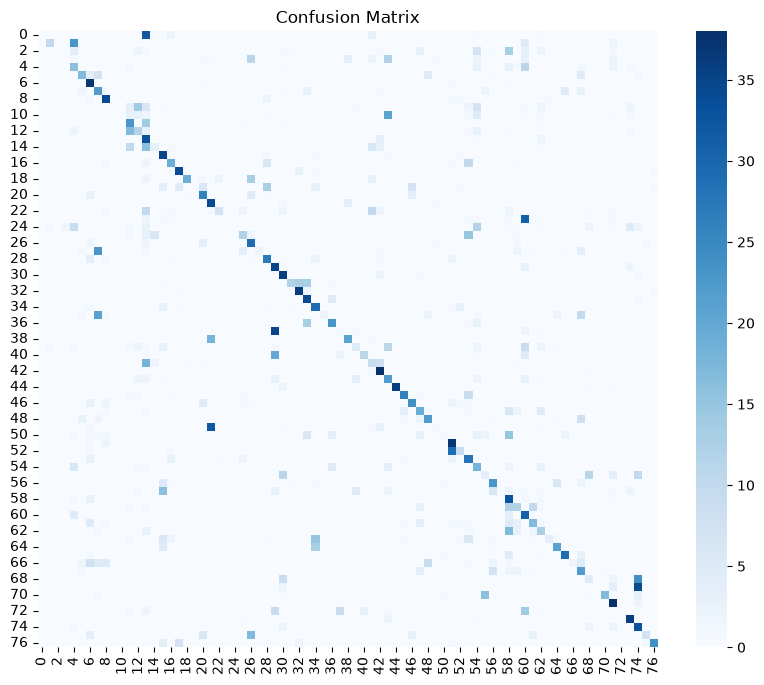

In [12]:
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=label_names
))

macro_f1 = f1_score(y_true, y_pred, average="macro")
print("Macro F1:", macro_f1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()